In [1]:
import pandas as pd

my_a = pd.read_csv("../data/processed/malaysia_part_a_jianru.csv")
my_b = pd.read_csv("../data/processed/malaysia_part_b_sutong.csv")

print("Part A shape:", my_a.shape)
print("Part B shape:", my_b.shape)

print("\nPart A columns:")
print(my_a.columns.tolist())

print("\nPart B columns:")
print(my_b.columns.tolist())

Part A shape: (1313, 5)
Part B shape: (1313, 7)

Part A columns:
['D_INTERVIEW', 'Q131_cat', 'Q138_cat', 'gender_cat', 'Q262']

Part B columns:
['D_INTERVIEW', 'edu', 'household_income', 'em', 'marriage', 'victim_self', 'victim_family']


In [2]:
my = pd.merge(
    my_a,
    my_b,
    on="D_INTERVIEW",
    how="inner"
)

print("Merged Malaysia shape:", my.shape)
print("Unique IDs:", my["D_INTERVIEW"].nunique())
print("Duplicate IDs:", my["D_INTERVIEW"].duplicated().sum())

my.head()

Merged Malaysia shape: (1313, 11)
Unique IDs: 1313
Duplicate IDs: 0


,D_INTERVIEW,Q131_cat,Q138_cat,gender_cat,Q262,edu,household_income,em,marriage,victim_self,victim_family
0,458070001.0,2,4,2,18.0,2.0,2.0,0,0,0,1
1,458070002.0,2,4,1,19.0,0.0,3.0,1,0,0,0
2,458070003.0,2,4,1,49.0,2.0,3.0,1,1,0,0
3,458070004.0,4,3,2,47.0,2.0,5.0,1,1,0,0
4,458070005.0,2,3,2,38.0,6.0,4.0,1,1,0,0


In [3]:
my.to_csv(
    "../data/processed/malaysia_cleaned.csv",
    index=False
)

In [4]:
print(my_a.columns.tolist())

['D_INTERVIEW', 'Q131_cat', 'Q138_cat', 'gender_cat', 'Q262']


In [5]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

sg = pd.read_csv("../data/processed/singapore_pool_ready.csv")
my = pd.read_csv("../data/processed/malaysia_pool_ready.csv")

print("SG shape:", sg.shape)
print("MY shape:", my.shape)
print("\nSG columns:", sg.columns.tolist())
print("\nMY columns:", my.columns.tolist())

SG shape: (2012, 11)
MY shape: (1313, 11)

SG columns: ['security_r', 'harassment_r', 'gender_bi', 'age', 'edu', 'household_income', 'em', 'marriage', 'victim_self', 'victim_family', 'country']

MY columns: ['security_r', 'harassment_r', 'gender_bi', 'age', 'edu', 'household_income', 'em', 'marriage', 'victim_self', 'victim_family', 'country']


In [6]:
pooled = pd.concat([sg, my], ignore_index=True)

print("Pooled shape:", pooled.shape)
print("\nCountry counts:")
print(pooled["country"].value_counts())

pooled.head()

Pooled shape: (3325, 11)

Country counts:
country
0    2012
1    1313
Name: count, dtype: int64


,security_r,harassment_r,gender_bi,age,edu,household_income,em,marriage,victim_self,victim_family,country
0,3.0,1.0,1,37.0,7.0,5.0,1,1,0.0,0.0,0
1,3.0,1.0,1,42.0,6.0,1.0,1,0,NaN,1.0,0
2,3.0,2.0,0,28.0,6.0,4.0,1,0,0.0,0.0,0
3,3.0,2.0,1,30.0,6.0,6.0,1,1,0.0,0.0,0
4,4.0,1.0,1,32.0,3.0,8.0,0,1,0.0,0.0,0


In [7]:
vars_to_check = [
    "security_r",
    "harassment_r",
    "gender_bi",
    "em",
    "marriage",
    "victim_self",
    "victim_family"
]

for var in vars_to_check:
    print("\n====================")
    print(var)
    print("====================")
    print(
        pooled.groupby("country")[var]
        .value_counts(dropna=False)
        .sort_index()
    )


security_r
country  security_r
0        1.0              9
         2.0            152
         3.0           1093
         4.0            756
         NaN              2
1        1.0             72
         2.0            488
         3.0            630
         4.0            123
Name: count, dtype: int64

harassment_r
country  harassment_r
0        1.0             1453
         2.0              466
         3.0               66
         4.0               16
         NaN               11
1        1.0              503
         2.0              509
         3.0              217
         4.0               84
Name: count, dtype: int64

gender_bi
country  gender_bi
0        0             924
         1            1088
1        0             657
         1             656
Name: count, dtype: int64

em
country  em
0        0      720
         1     1292
1        0      340
         1      973
Name: count, dtype: int64

marriage
country  marriage
0        0            803
         1        

In [8]:
import statsmodels.formula.api as smf

model1 = smf.ols(
    """
    security_r ~ harassment_r + country + gender_bi
    + age + edu + household_income + em
    + marriage + victim_self + victim_family
    """,
    data=pooled
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:             security_r   R-squared:                       0.293
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     133.8
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          1.92e-234
Time:                        19:10:53   Log-Likelihood:                -3092.7
No. Observations:                3238   AIC:                             6207.
Df Residuals:                    3227   BIC:                             6274.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            3.9736      0.067  

In [9]:
model2 = smf.ols(
    """
    security_r ~ harassment_r + country + gender_bi
    + harassment_r:country
    + harassment_r:gender_bi
    + age + edu + household_income + em
    + marriage + victim_self + victim_family
    """,
    data=pooled
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:             security_r   R-squared:                       0.294
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     112.0
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          2.77e-233
Time:                        19:10:54   Log-Likelihood:                -3090.4
No. Observations:                3238   AIC:                             6207.
Df Residuals:                    3225   BIC:                             6286.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  3

In [16]:
model3 = smf.ols(
    """
    security_r ~ harassment_r + country + gender_bi
    + harassment_r:country
    + age + edu + household_income + em
    + marriage + victim_self + victim_family
    """,
    data=pooled
).fit()

print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:             security_r   R-squared:                       0.294
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     122.1
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          3.19e-234
Time:                        19:17:02   Log-Likelihood:                -3090.7
No. Observations:                3238   AIC:                             6205.
Df Residuals:                    3226   BIC:                             6278.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                3.9163 

In [11]:
print("Model 1 R²:", model1.rsquared)
print("Model 2 R²:", model2.rsquared)

print(model2.compare_f_test(model1))

Model 1 R²: 0.2930786078587668
Model 2 R²: 0.29406413710474466
(np.float64(2.2511477212980338), np.float64(0.10544373214614908), np.float64(2.0))


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
terms = [
    "harassment_r",
    "country",
    "gender_bi",
    "harassment_r:country",
    "harassment_r:gender_bi"
]

plot_df = pd.DataFrame({
    "term": terms,
    "coef": model2.params[terms],
    "lower": model2.conf_int().loc[terms, 0],
    "upper": model2.conf_int().loc[terms, 1],
    "p": model2.pvalues[terms]
})

plot_df

,term,coef,lower,upper,p
harassment_r,harassment_r,-0.220890,-0.279224,-0.162556,1.441484e-13
country,country,-0.468661,-0.578696,-0.358627,9.917402e-17
gender_bi,gender_bi,-0.149229,-0.247290,-0.051168,2.868361e-03
harassment_r:country,harassment_r:country,-0.062532,-0.124921,-0.000144,4.947546e-02
harassment_r:gender_bi,harassment_r:gender_bi,0.020989,-0.035050,0.077028,4.627809e-01


In [14]:
labels = {
    "harassment_r": "Harassment",
    "country": "Malaysia",
    "gender_bi": "Female",
    "harassment_r:country": "Harassment × Malaysia",
    "harassment_r:gender_bi": "Harassment × Female"
}

plot_df["label"] = plot_df["term"].map(labels)

plot_df

,term,coef,lower,upper,p,label
harassment_r,harassment_r,-0.220890,-0.279224,-0.162556,1.441484e-13,Harassment
country,country,-0.468661,-0.578696,-0.358627,9.917402e-17,Malaysia
gender_bi,gender_bi,-0.149229,-0.247290,-0.051168,2.868361e-03,Female
harassment_r:country,harassment_r:country,-0.062532,-0.124921,-0.000144,4.947546e-02,Harassment × Malaysia
harassment_r:gender_bi,harassment_r:gender_bi,0.020989,-0.035050,0.077028,4.627809e-01,Harassment × Female


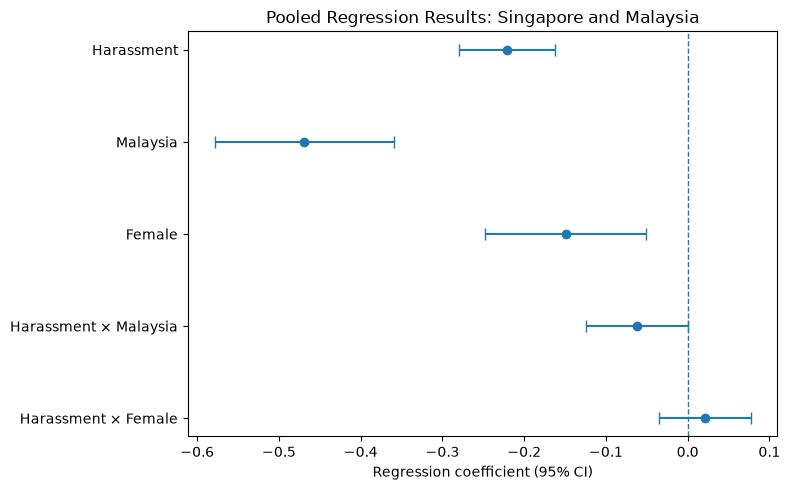

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

y_pos = range(len(plot_df))

ax.errorbar(
    plot_df["coef"],
    y_pos,
    xerr=[
        plot_df["coef"] - plot_df["lower"],
        plot_df["upper"] - plot_df["coef"]
    ],
    fmt="o",
    capsize=4
)

ax.axvline(0, linestyle="--", linewidth=1)

ax.set_yticks(list(y_pos))
ax.set_yticklabels(plot_df["label"])

ax.set_xlabel("Regression coefficient (95% CI)")
ax.set_title("Pooled Regression Results: Singapore and Malaysia")

ax.invert_yaxis()

plt.tight_layout()
plt.show()